# Notebook 16 — Kepler DR25 TCE candidate investigation

**Purpose:** retrieve DR25 Threshold-Crossing Events (TCEs), compare them with the KOI catalog, create a cautious shortlist of TCEs without a close-period KOI match, and optionally inspect public Kepler light curves.

**This is not a planet-discovery pipeline.** A TCE is a signal detected by the pipeline, not a confirmed planet. A TCE without a KOI match may have many explanations, including instrumental/systematic effects, eclipsing binaries, or an already-known object represented differently in the catalogs. Any shortlist requires expert vetting and independent validation.

NASA recommends accessing the DR25 TCE table through TAP; legacy API support for this table was discontinued.

In [3]:
%pip -q install pandas numpy matplotlib requests

Note: you may need to restart the kernel to use updated packages.


In [4]:

import io
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

TAP_SYNC = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
TAP_TABLES = "https://exoplanetarchive.ipac.caltech.edu/TAP/tables"
SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "StudentResearch-Exoplanet-Project/1.0"})

def tap_query(query, timeout=240):
    """Run an Exoplanet Archive TAP synchronous query and return a DataFrame."""
    response = SESSION.get(
        TAP_SYNC,
        params={"query": query, "format": "csv"},
        timeout=timeout
    )
    print("HTTP:", response.status_code, "| Content-Type:", response.headers.get("Content-Type"))
    response.raise_for_status()
    body = response.text.strip()
    if not body:
        raise RuntimeError("NASA TAP returned an empty response.")
    if body.startswith("<") or "QUERY_STATUS" in body[:500].upper():
        raise RuntimeError("NASA TAP returned XML/error text instead of CSV:\n" + body[:1200])
    try:
        frame = pd.read_csv(io.StringIO(body))
    except Exception as exc:
        raise RuntimeError("Could not parse NASA TAP CSV. First response text:\n" + body[:1200]) from exc
    if len(frame.columns) == 0:
        raise RuntimeError("NASA TAP response contained no columns.")
    frame.columns = [str(c).strip().lower() for c in frame.columns]
    return frame

def get_columns(table_name):
    """Try TAP_SCHEMA first, then fall back to SELECT TOP 1 *."""
    schema_query = (
        "SELECT column_name FROM TAP_SCHEMA.columns "
        f"WHERE table_name = '{table_name}'"
    )
    try:
        schema = tap_query(schema_query, timeout=120)
        cols = set(schema["column_name"].astype(str).str.lower())
        if cols:
            print(f"Found {len(cols)} columns through TAP_SCHEMA for {table_name}.")
            return cols
    except Exception as exc:
        print("TAP_SCHEMA lookup failed; trying direct table query:", str(exc)[:250])

    sample = tap_query(f"SELECT TOP 1 * FROM {table_name}", timeout=180)
    cols = set(sample.columns)
    if not cols:
        raise RuntimeError(f"Could not discover columns for {table_name}.")
    print(f"Found {len(cols)} columns through direct query for {table_name}.")
    return cols

def choose_columns(available, preferred, required=()):
    chosen = [c for c in preferred if c in available]
    missing = [c for c in required if c not in available]
    if missing:
        raise RuntimeError(f"Required columns missing: {missing}. Available columns include: {sorted(available)[:80]}")
    return chosen

def sql_select(table, columns, top=None):
    if not columns:
        raise ValueError(f"No columns selected for {table}")
    top_sql = f"TOP {int(top)} " if top else ""
    return f"SELECT {top_sql}{', '.join(columns)} FROM {table}"


## 1. Discover the TCE and KOI table columns

In [5]:

TCE_TABLE = "q1_q17_dr25_tce"
KOI_TABLE = "q1_q17_dr25_koi"

tce_cols = get_columns(TCE_TABLE)
koi_cols = get_columns(KOI_TABLE)

print("\nTCE columns:", sorted(tce_cols))
print("\nKOI columns:", sorted(koi_cols))

required_tce = {"kepid", "tce_period", "tce_time0bk"}
missing = required_tce - tce_cols
if missing:
    raise RuntimeError(
        f"Required TCE columns are missing: {sorted(missing)}. "
        f"Available columns: {sorted(tce_cols)}"
    )


HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
Found 158 columns through direct query for q1_q17_dr25_tce.
HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
Found 153 columns through direct query for q1_q17_dr25_koi.

TCE columns: ['av_pp_afp', 'av_pp_ntp', 'av_pp_pc', 'av_pred_class', 'av_training_set', 'av_vf_afp', 'av_vf_afp_err', 'av_vf_ntp', 'av_vf_ntp_err', 'av_vf_pc', 'av_vf_pc_err', 'boot_fap', 'boot_mesmean', 'boot_messtd', 'boot_mesthresh', 'dec', 'kepid', 'ra', 'rowupdate', 'tce_albedo', 'tce_albedo_err', 'tce_albedo_stat', 'tce_bin_oedp_stat', 'tce_cap_stat', 'tce_chisq1', 'tce_chisq2', 'tce_chisqgof', 'tce_chisqgofdof', 'tce_datalink_dvr', 'tce_datalink_dvs', 'tce_delivname', 'tce_depth', 'tce_depth_err', 'tce_dicco_mdec', 'tce_dicco_mdec_err', 'tce_dicco_mra', 'tce_dicco_mra_err', 'tce_dicco_msky', 'tce_dicco_msky_err', 'tce_dikco_mdec', 'tce_dikco_mdec_err', 'tce_dikco_mra', 'tce_dikco_mra_err', 'tce_dikco_msky', 'tce_di

## 2. Download a compact set of TCE and KOI fields

In [6]:

tce_preferred = [
    "kepid", "tce_plnt_num", "tce_period", "tce_time0bk",
    "tce_duration", "tce_model_snr", "tce_rogue_flag"
]
koi_preferred = [
    "kepid", "kepoi_name", "koi_disposition", "koi_period",
    "koi_time0bk", "koi_prad"
]

tce_selected = choose_columns(
    tce_cols, tce_preferred,
    required=("kepid", "tce_period", "tce_time0bk")
)
koi_selected = choose_columns(
    koi_cols, koi_preferred,
    required=("kepid", "koi_period", "koi_disposition")
)

tces = tap_query(sql_select(TCE_TABLE, tce_selected))
kois = tap_query(sql_select(KOI_TABLE, koi_selected))

for col in ["kepid", "tce_period", "tce_time0bk", "tce_model_snr", "tce_rogue_flag"]:
    if col in tces.columns:
        tces[col] = pd.to_numeric(tces[col], errors="coerce")
for col in ["kepid", "koi_period"]:
    if col in kois.columns:
        kois[col] = pd.to_numeric(kois[col], errors="coerce")

print("TCE rows:", len(tces), "| KOI rows:", len(kois))
display(tces.head())


HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
TCE rows: 34032 | KOI rows: 8054


,kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_model_snr,tce_rogue_flag
0,2304168,2,431.719000,219.298,13.220,10.320,0
1,2304235,1,0.570607,132.049,1.160,20.390,0
2,2304566,1,0.689480,131.833,5.236,2.574,0
3,2304320,1,16.540800,133.952,2.715,30.830,0
4,2303365,2,0.520697,132.003,1.035,18.950,0


## 3. Remove flagged rogue detections when the flag exists

In [7]:

tces_clean = tces.copy()
if "tce_rogue_flag" in tces_clean.columns:
    before = len(tces_clean)
    # DR25 documentation defines the rogue flag; retain rows explicitly marked 0.
    tces_clean = tces_clean[tces_clean["tce_rogue_flag"].eq(0)].copy()
    print(f"Removed {before - len(tces_clean)} rows not explicitly flagged as non-rogue.")
else:
    print("WARNING: rogue flag unavailable; no rogue-event filtering was possible.")

# Use the primary transit-model SNR when available. Do not rank by tce_maxmes:
# that parameter is associated with the weak-secondary-event statistic.
if "tce_model_snr" in tces_clean.columns:
    tces_clean = tces_clean.sort_values("tce_model_snr", ascending=False, na_position="last")


Removed 1498 rows not explicitly flagged as non-rogue.


## 4. Cross-match TCEs to KOIs by host star and period

In [8]:

# A relative period tolerance of 1% is used only to identify approximate catalog
# counterparts. It is not a physical validation criterion.
kois_valid = kois.dropna(subset=["kepid", "koi_period"]).copy()
kois_valid["kepid"] = kois_valid["kepid"].astype("int64")
tces_valid = tces_clean.dropna(subset=["kepid", "tce_period"]).copy()
tces_valid["kepid"] = tces_valid["kepid"].astype("int64")

match_rows = []
for idx, tce in tces_valid.iterrows():
    same_star = kois_valid[kois_valid["kepid"].eq(tce["kepid"])].copy()
    if len(same_star):
        same_star["relative_period_difference"] = (
            (same_star["koi_period"] - tce["tce_period"]).abs() / tce["tce_period"]
        )
        best = same_star.sort_values("relative_period_difference").iloc[0]
        matched = bool(best["relative_period_difference"] <= 0.01)
        match_rows.append({
            "tce_row_index": idx,
            "kepid": int(tce["kepid"]),
            "tce_period": tce["tce_period"],
            "tce_time0bk": tce["tce_time0bk"],
            "tce_model_snr": tce.get("tce_model_snr", np.nan),
            "matched_koi": matched,
            "koi_name": best.get("kepoi_name", np.nan) if matched else np.nan,
            "koi_disposition": best.get("koi_disposition", np.nan) if matched else np.nan,
            "period_fractional_difference": best["relative_period_difference"] if matched else np.nan,
        })
    else:
        match_rows.append({
            "tce_row_index": idx,
            "kepid": int(tce["kepid"]),
            "tce_period": tce["tce_period"],
            "tce_time0bk": tce["tce_time0bk"],
            "tce_model_snr": tce.get("tce_model_snr", np.nan),
            "matched_koi": False,
            "koi_name": np.nan,
            "koi_disposition": np.nan,
            "period_fractional_difference": np.nan,
        })

matches = pd.DataFrame(match_rows)
unmatched = matches[~matches["matched_koi"]].copy()
print("TCEs evaluated:", len(matches))
print("Approximate KOI matches:", int(matches["matched_koi"].sum()))
print("TCEs without a close-period KOI match:", len(unmatched))
display(unmatched.head(25))


TCEs evaluated: 32534
Approximate KOI matches: 9086
TCEs without a close-period KOI match: 23448


,tce_row_index,kepid,tce_period,tce_time0bk,tce_model_snr,matched_koi,koi_name,koi_disposition,period_fractional_difference
1,8452,5288543,1.728540,131.807,40790.0,False,NaN,NaN,NaN
9,24535,9098810,4.129090,135.630,22190.0,False,NaN,NaN,NaN
19,12438,6949550,2.613690,133.974,15690.0,False,NaN,NaN,NaN
28,13614,6610219,5.650500,134.784,14860.0,False,NaN,NaN,NaN
49,26495,9641031,2.178170,133.110,10890.0,False,NaN,NaN,NaN
63,22482,8845221,2.701730,133.745,9847.0,False,NaN,NaN,NaN
101,12741,7025540,1.074110,131.690,7484.0,False,NaN,NaN,NaN
105,8355,5347784,4.792030,134.013,7351.0,False,NaN,NaN,NaN
106,4274,4157488,2.598710,132.568,7301.0,False,NaN,NaN,NaN
113,16650,7846730,5.514110,136.827,6989.0,False,NaN,NaN,NaN


## 5. Export the shortlist for documented follow-up

In [9]:

matches.to_csv("DR25_TCE_to_KOI_crossmatch.csv", index=False)
unmatched.to_csv("DR25_TCE_without_close_KOI_match.csv", index=False)

print("""
Interpretation: 'no close-period KOI match' means only that this simple
catalog cross-match did not find a KOI around the same KIC with a period
within 1%. It does not mean the signal is a planet, new, or scientifically
valid. Check catalog aliases, harmonics, data-quality flags, eclipsing-binary
indicators, centroid offsets, odd/even transit differences, and the literature.
""")



Interpretation: 'no close-period KOI match' means only that this simple
catalog cross-match did not find a KOI around the same KIC with a period
within 1%. It does not mean the signal is a planet, new, or scientifically
valid. Check catalog aliases, harmonics, data-quality flags, eclipsing-binary
indicators, centroid offsets, odd/even transit differences, and the literature.



## 6. Optional: inspect a public Kepler light curve

In [10]:

# Install Lightkurve only if you want to run this section.
%pip -q install lightkurve
import lightkurve as lk

if len(unmatched) == 0:
    print("No unmatched TCEs available for optional inspection.")
else:
    print("Choose a row number from this displayed shortlist:")
    display(unmatched.head(20).reset_index(drop=True))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
Choose a row number from this displayed shortlist:


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


,tce_row_index,kepid,tce_period,tce_time0bk,tce_model_snr,matched_koi,koi_name,koi_disposition,period_fractional_difference
0,8452,5288543,1.728540,131.807,40790.0,False,NaN,NaN,NaN
1,24535,9098810,4.129090,135.630,22190.0,False,NaN,NaN,NaN
2,12438,6949550,2.613690,133.974,15690.0,False,NaN,NaN,NaN
3,13614,6610219,5.650500,134.784,14860.0,False,NaN,NaN,NaN
4,26495,9641031,2.178170,133.110,10890.0,False,NaN,NaN,NaN
5,22482,8845221,2.701730,133.745,9847.0,False,NaN,NaN,NaN
6,12741,7025540,1.074110,131.690,7484.0,False,NaN,NaN,NaN
7,8355,5347784,4.792030,134.013,7351.0,False,NaN,NaN,NaN
8,4274,4157488,2.598710,132.568,7301.0,False,NaN,NaN,NaN
9,16650,7846730,5.514110,136.827,6989.0,False,NaN,NaN,NaN


Inspecting KIC 5288543; period=1.728540 days; epoch(BKJD)=131.807000
SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 01 2009 Kepler      60 kplr005288543      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr005288543      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr005288543      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr005288543      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr005288543      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr005288543      0.0
  6 Kepler Quarter 07 2010 Kepler    1800 kplr005288543      0.0
  7 Kepler Quarter 08 2011 Kepler    1800 kplr005288543      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr005288543      0.0
  9 Kepler Quarter 11 2012 Kepler    1800 kplr005288543      0.0
 10 Kepler Quarter 12 2012 Kepler    1800 k

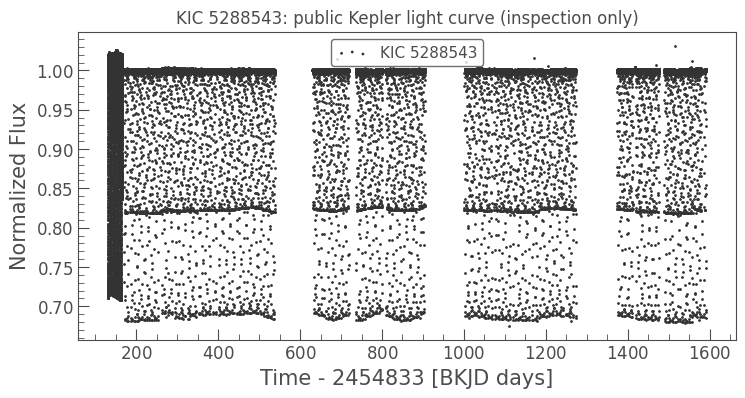

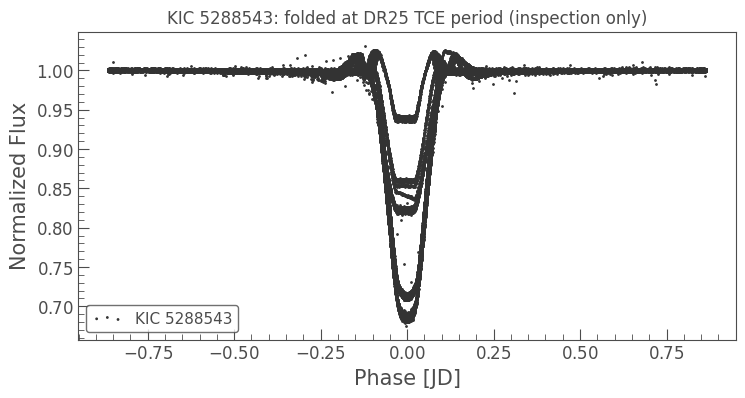

In [11]:

# Set this to a row number in unmatched.reset_index(drop=True).
# Start with 0 to inspect the first row in the displayed shortlist.
SHORTLIST_ROW = 0

shortlist = unmatched.reset_index(drop=True)
if not (0 <= SHORTLIST_ROW < len(shortlist)):
    raise IndexError("SHORTLIST_ROW is outside the displayed shortlist.")

candidate = shortlist.iloc[SHORTLIST_ROW]
kepid = int(candidate["kepid"])
period = float(candidate["tce_period"])
epoch_bkjd = float(candidate["tce_time0bk"])

print(f"Inspecting KIC {kepid}; period={period:.6f} days; epoch(BKJD)={epoch_bkjd:.6f}")
search_result = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler")
print(search_result)

if len(search_result) == 0:
    print("No public Kepler light curve was returned for this target.")
else:
    lc_collection = search_result.download_all()
    if lc_collection is None or len(lc_collection) == 0:
        print("Lightkurve found search results but could not download light curves.")
    else:
        lc = lc_collection.stitch().remove_nans()
        try:
            flat = lc.flatten(window_length=401)
        except Exception:
            flat = lc
        flat.scatter()
        plt.title(f"KIC {kepid}: public Kepler light curve (inspection only)")
        plt.show()

        # Kepler time is commonly represented in BKJD by Lightkurve.
        # If the time format/zero point differs, this fold may be offset;
        # verify the time convention before interpreting the plot.
        folded = flat.fold(period=period, epoch_time=epoch_bkjd)
        folded.scatter()
        plt.title(f"KIC {kepid}: folded at DR25 TCE period (inspection only)")
        plt.show()


## 7. What this notebook does—and does not—establish

It retrieves archived pipeline detections, checks for approximate KOI counterparts, and supports preliminary visualization. It does **not** confirm a planet or establish a discovery.

Before any claim about a potentially new object, a qualified research mentor should help verify the signal against the full Kepler data products and literature, assess instrumental and astrophysical false-positive scenarios, and determine whether independent follow-up is possible. Report this notebook's output as a *candidate-screening exercise*.